Pandas version: 3.0.6
  Category                                            Message
0      ham  Go until jurong point, crazy.. Available only ...
1      ham                      Ok lar... Joking wif u oni...
2     spam  Free entry in 2 a wkly comp to win FA Cup fina...
3      ham  U dun say so early hor... U c already then say...
4      ham  Nah I don't think he goes to usf, he lives aro...
<class 'pandas.DataFrame'>
RangeIndex: 5573 entries, 0 to 5572
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Category  5573 non-null   str  
 1   Message   5573 non-null   str  
dtypes: str(2)
memory usage: 87.2 KB


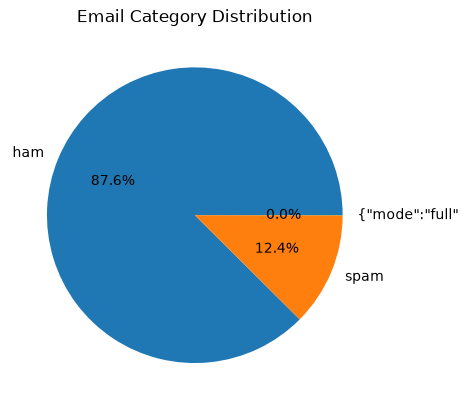

c:\Users\Rohit Pawar\Downloads\SPAMEMAIL\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 146 (\x92) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\Rohit Pawar\Downloads\SPAMEMAIL\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 148 (\x94) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\Rohit Pawar\Downloads\SPAMEMAIL\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 145 (\x91) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\Rohit Pawar\Downloads\SPAMEMAIL\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 147 (\x93) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\Rohit Pawar\Downloads\SPAMEMAIL\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 150 (\x96) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(b

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Pandas version:", pd.__version__)

df = pd.read_csv("email.csv")

print(df.head())
df.tail(1)
df.shape
df.dtypes
df.info()
df.isnull().sum().sum()
df.duplicated().sum()/df.shape[0]
df.drop_duplicates(inplace= True)
df["Category"].value_counts()
df["Category"].value_counts(normalize=True)* 100
df["Category"].value_counts().plot(
    kind = "pie",
    autopct = "%1.1f%%"
)
plt.ylabel("")
plt.title("Email Category Distribution")
plt.show()
df["Message_Length"]=df["Message"].apply(len)
df["Message"][1]
df["Message_Length"].describe()
sns.histplot(df["Message"],bins=20)
plt.title("Distribution of Message Length")
plt.xlabel("Characters")
plt.show()
sns.boxplot(
    data = df,
    x = "Category",
    y = "Message_Length"
)
plt.title("Message Length by category")
plt.show()




In [ ]:
df.groupby("Category")["Message_Length"].mean()

Category
ham                70.869353
spam              137.118565
{"mode":"full"     15.000000
Name: Message_Length, dtype: float64

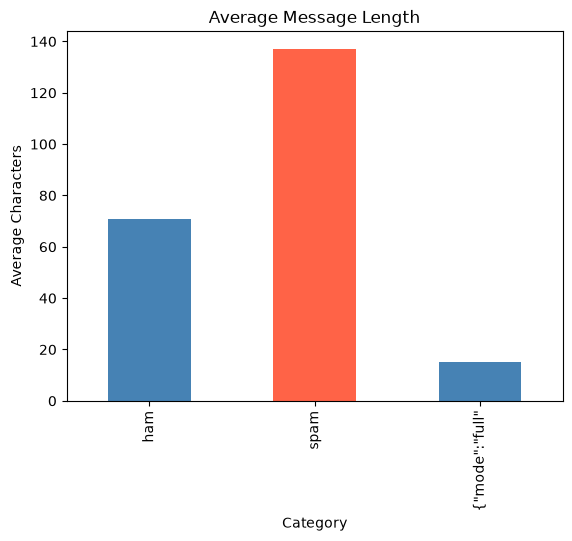

In [ ]:
df.groupby("Category")["Message_Length"].mean().plot(
    kind = "bar",
    color = ["steelblue","tomato"]

)
plt.ylabel("Average Characters")
plt.title("Average Message Length")
plt.show()

In [ ]:
df.head()

,Category,Message,Message_Length
0,ham,"Go until jurong point, crazy.. Available only ...",111
1,ham,Ok lar... Joking wif u oni...,29
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,ham,U dun say so early hor... U c already then say...,49
4,ham,"Nah I don't think he goes to usf, he lives aro...",61


In [ ]:
df["Word_Count"]=df["Message"].apply(lambda x: len(x.split()))

In [ ]:
df.head()

,Category,Message,Message_Length,Word_Count
0,ham,"Go until jurong point, crazy.. Available only ...",111,20
1,ham,Ok lar... Joking wif u oni...,29,6
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155,28
3,ham,U dun say so early hor... U c already then say...,49,11
4,ham,"Nah I don't think he goes to usf, he lives aro...",61,13


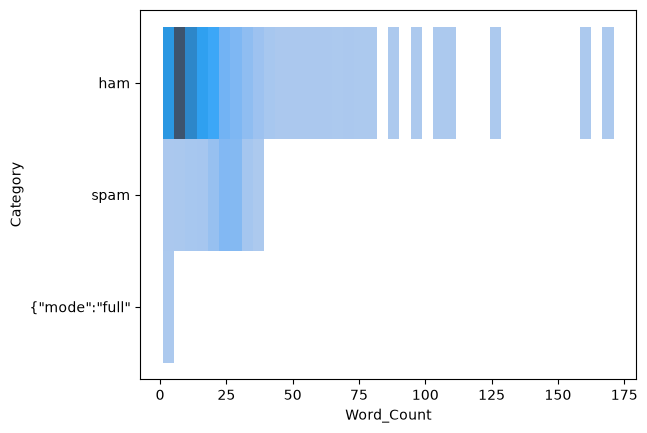

In [ ]:
sns.histplot(
data = df,
x = "Word_Count",
y = "Category",
bins = 40
)
plt.show()

In [ ]:
df.groupby("Category")["Word_Count"].mean()

Category
ham               14.239814
spam              23.659906
{"mode":"full"     1.000000
Name: Word_Count, dtype: float64

In [ ]:
import pandas as pd

df = pd.read_csv("email.csv")

print(df.head())
print(df.shape)

df[df["Category"] == "ham"].sample(5, random_state=1)

  Category                                            Message
0      ham  Go until jurong point, crazy.. Available only ...
1      ham                      Ok lar... Joking wif u oni...
2     spam  Free entry in 2 a wkly comp to win FA Cup fina...
3      ham  U dun say so early hor... U c already then say...
4      ham  Nah I don't think he goes to usf, he lives aro...
(5573, 2)


,Category,Message
2535,ham,Ok enjoy . R u there in home.
1213,ham,"Yo, the game almost over? Want to go to walmar..."
522,ham,Shall i come to get pickle
5398,ham,Hi. Hope you had a good day. Have a better night.
700,ham,K..u also dont msg or reply to his msg..


In [ ]:
df["Category"] = df["Category"].map({
    "ham": 0,
    "spam" : 1
    })

In [ ]:
df.head()

,Category,Message
0,0.0,"Go until jurong point, crazy.. Available only ..."
1,0.0,Ok lar... Joking wif u oni...
2,1.0,Free entry in 2 a wkly comp to win FA Cup fina...
3,0.0,U dun say so early hor... U c already then say...
4,0.0,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
import warnings
warnings.filterwarnings("ignore")

In [ ]:
from sklearn.model_selection import train_test_split



In [ ]:
x= df["Message"]


In [ ]:
y=df["Category"]


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("email.csv")

df = df.drop_duplicates()

# Keep only valid spam/ham categories
df = df[df["Category"].isin(["ham", "spam"])]

x = df["Message"]
y = df["Category"]

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)



In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(
    stop_words = "english",
    max_features = 5000,
    ngram_range=(1,2)
)

In [ ]:
x_train_tfidf = tfidf.fit_transform(x_train)

In [ ]:
x_test_tfidf = tfidf.transform(x_test)

In [ ]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

In [ ]:
models = {
    "Naive Bayes":(
        MultinomialNB(),

        {
            "alpha": [0.1,0.5,1,2,5]
}
    ),
    "LogisticRegression":(
        LogisticRegression(
            class_weight="balanced",
            max_iter=1000
        ),
        {
            "C": [0.01,0.1,1,10,100]
        }

    ),
    "Linear SVM":(
        LinearSVC(
            class_weight="balanced"
        ),
    
    {
        "C" : [0.01,0.1,1,10]
    }
    ),
    "Random Forest": (
      RandomForestClassifier(
          class_weight= "balanced"
      ),
      {
          "n_estimators" : [100,200,300],
          "max_depth" : [10,20,None],
          "min_samples_split" : [2,5,10]

      }
    ),
    "Decision Tree": (
        DecisionTreeClassifier(
            class_weight="balanced"
        ),
        {
            "max_depth" : [5,10,20, None],
            "min_samples_split" : [2,5,10]
        }
    ),
    "Gradient Boosting": (
        GradientBoostingClassifier(),
        {
            "n_estimators":[100,200],
            "learning_rate":[0.01,0.05,0.1],
            "max_depth": [3,5]
        }
    ),
    "KNN":(
        KNeighborsClassifier(),
        {
            "n_neighbors":[3,5,7,9]
        }
    )
}

In [11]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

# Define models
models = {
    "Naive Bayes": (
        MultinomialNB(),
        {
            "alpha": [0.1, 0.5, 1, 2, 5]
        }
    ),

    "Logistic Regression": (
        LogisticRegression(
            class_weight="balanced",
            max_iter=1000
        ),
        {
            "C": [0.01, 0.1, 1, 10, 100]
        }
    ),

    "Linear SVM": (
        LinearSVC(
            class_weight="balanced"
        ),
        {
            "C": [0.01, 0.1, 1, 10]
        }
    ),

    "Random Forest": (
        RandomForestClassifier(
            class_weight="balanced",
            random_state=42
        ),
        {
            "n_estimators": [100, 200, 300],
            "max_depth": [10, 20, None],
            "min_samples_split": [2, 5, 10]
        }
    ),

    "Decision Tree": (
        DecisionTreeClassifier(
            class_weight="balanced",
            random_state=42
        ),
        {
            "max_depth": [5, 10, 20, None],
            "min_samples_split": [2, 5, 10]
        }
    ),

    "Gradient Boosting": (
        GradientBoostingClassifier(
            random_state=42
        ),
        {
            "n_estimators": [100, 200],
            "learning_rate": [0.01, 0.05, 0.1],
            "max_depth": [3, 5]
        }
    ),

    "KNN": (
        KNeighborsClassifier(),
        {
            "n_neighbors": [3, 5, 7, 9]
        }
    )
}

print("Models defined successfully!")
print(models.keys())

Models defined successfully!
dict_keys(['Naive Bayes', 'Logistic Regression', 'Linear SVM', 'Random Forest', 'Decision Tree', 'Gradient Boosting', 'KNN'])


In [ ]:
results = [] 
 
best_models = {} 
 
for name, (model, params) in models.items(): 
 
    search = RandomizedSearchCV( 
        estimator=model, 
        param_distributions=params, 
        n_iter=10, 
        cv=5, 
        scoring="f1", 
        n_jobs=-1, 
        random_state=42 
    ) 
 
    search.fit(x_train_tfidf, y_train) 
 
    best_model = search.best_estimator_ 
 
    best_models[name] = best_model 
 
    predictions = best_model.predict(x_test_tfidf) 
 
    accuracy = accuracy_score(y_test, predictions) 
    precision = precision_score(y_test, predictions) 
    recall = recall_score(y_test, predictions) 
    f1 = f1_score(y_test, predictions) 
 
    try: 
        auc = roc_auc_score( 
            y_test, 
            best_model.predict_proba(x_test_tfidf)[:, 1] 
        ) 
    except: 
        auc = np.nan 
 
    results.append({ 
        "Model": name, 
        "Accuracy": accuracy, 
        "Precision": precision, 
        "Recall": recall, 
        "F1 Score": f1, 
        "ROC AUC": auc, 
        "Best Params": search.best_params_ 
    }) make a code the will define model